# Initalize libraries

## Import libraries

In [75]:
import sys, os
import time
from os.path import join
from os import path
from importlib import reload
from getpass import getuser
from tqdm.auto import tqdm
import scipy

import skimage
#data
import xarray as xr
import h5py

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import LogNorm

# pyFAI
import pyFAI
from pyFAI.azimuthalIntegrator import AzimuthalIntegrator
from pyFAI.detectors import Detector

# Self-written libraries
sys.path.append(join(os.getcwd(), "library"))
import helper_functions as helper
import interactive
from interactive import cimshow
import mask_lib

# Gifs
import imageio


from scipy.ndimage import map_coordinates

plt.rcParams["figure.constrained_layout.use"] = True  # replaces plt.tight_layout

In [76]:
# Is there a GPU?
try:
    # Cupy
    import cupy as cp
    import cupyx as cpx

    GPU = True

    print("GPU available")

    # Self-written library
    import CCI_core_cupy as cci
except:
    GPU = False
    import CCI_core as cci

    print("GPU unavailable")

parula_map = cci.parula_map()

GPU unavailable


In [77]:
# interactive plotting
import ipywidgets

%matplotlib widget

# Auto formatting of cells
#%load_ext jupyter_black

## Experiment specific Functions

In [78]:
facility = "PETRA" # Options: "SwissFEL", "MAXI"
BEAMTIMEID = 11022228 # Proposal number
data_fname_prefix = "2602_orbitronics"
USER = getuser()

# Number or jobs for analysis
NR_JOBS = 32

# Facility specific loading functions
if facility == "PETRA":
    import PETRA_MaxP04_loading as loading
elif facility == "MAXI":
    import MAXI_loading as loading
elif facility == "SwissFEL":
    from sfdata import SFDataFiles, SFScanInfo, SFProcFile
    import Swiss_FEL_Loading as loading

BASEFOLDER = "/asap3/petra3/gpfs/p04/2026/data/%s/" % BEAMTIMEID
DATAFOLDER = join(BASEFOLDER,"raw")

reload(loading)
# Load dictionary for keys etc
mnemonics = loading.load_mnemonics()

### Loading

In [79]:
def line_scan(image, x1, y1, x2, y2, num=None):
    # Length of the line
    length = int(np.hypot(x2 - x1, y2 - y1))
    
    if num is None:
        num = length

    # Generate line coordinates
    x = np.linspace(x1, x2, num)
    y = np.linspace(y1, y2, num)

    # Extract values with interpolation
    coords = np.vstack((y, x))  # note: (row, col) = (y, x)
    values = map_coordinates(image, coords, order=1)

    return values





In [80]:
def generate_filename(scan_nr: int):
    """
    Generates filename of the given scan id

    Parameter
    =========
    scan_nr : number identifier (id) of the given scan

    Output
    ======
    filename : str
        full generated filename
    ======
    author: ck 2025
    """
    return join(DATAFOLDER, f"{data_fname_prefix}_{scan_nr:05d}.nxs")

def get_marana_filenames(scan_nr: int, file_indices = None):
    """
    Generates filename of the given scan id

    Parameter
    =========
    scan_nr : number identifier (id) of the given scan

    Output
    ======
    filename : str
        full generated filename
    ======
    author: ck 2025
    """

    scan_count = load_key(scan_nr, "/scan/data/point_nb")
    if np.ndim(scan_count) == 0:
        scan_count = 1
    elif np.ndim(scan_count) > 0:
        scan_count = scan_count.shape[0]

    #this does not work anymore since we are sampling with 200 frames per file -> os.listdir....
    
    names = os.listdir(join(DATAFOLDER, f"{data_fname_prefix}_{scan_nr:05d}","marana"))
    names = [name for name in names if name[-2:]=="nx"]
    fnames = np.array([join(DATAFOLDER, f"{data_fname_prefix}_{scan_nr:05d}","marana",name) for name in names])
    fnames = np.array(sorted(fnames))
    files = []
    for file in fnames:
        with h5py.File(file, "r") as f:
            if len(f["/entry/instrument/detector/timestamps"][()]) > 3:
                files.append(file)
    fnames = np.array(files)
    if file_indices is not None:
        fnames = fnames[file_indices]
    
        if type(fnames) == str:
            fnames = np.array([fnames])

    
    return fnames

def load_data(scan_id, keypath=mnemonics["collection"], keys=None):
    """
    Load data of all specified keys from keypath

    Parameter
    =========
    scan_id : int
        experimental identifier of scan
    keypath : str
        path of nexus file tree to relevant data field
    keys : str or list of strings
        keys to load from keypath

    Output
    ======
    data : dict
        data dictionary of keys
    ======
    author: ck 2024
    """

    # Generate filename from scan_id
    fname = generate_filename(scan_id)

    # load data with basic loading function
    data = loading.load_data(fname, keypath, keys=keys)

    return data


def load_key(scan_id, key):
    """
    Load any kind of data specified by key (path)

    Parameter
    =========
    scan_id : int
        experimental identifier of scan
    key : str
        key path of nexus file tree to relevant data field

    Output
    ======
    data : dict
        data dictionaray on single key
    ======
    author: ck 2024
    """
    # Generate filename from scan_id
    fname = generate_filename(scan_id)
    # load data with basic loading function
    data = loading.load_key(fname, key)

    return data
    
def load_images(im_id, file_indices = None):
    """
    Loads images for a given scan id

    Parameter
    =========
    im_id : int
        experimental identifier of image scan

    Output
    ======
    images : array
        stack of all images the correspond to the id
    ======
    author: ck 2024
    """

    # Generate filesnames
    fnames  = get_marana_filenames(im_id, file_indices = file_indices)

    # load data
    images = [loading.load_key(fname,mnemonics["nx_marana"]) for fname in tqdm(fnames)]
    images = np.stack(images)
    
    return images.astype("float32")

# Full image loading procedure
def load_processing(im_id, file_indices = None, binning = 1, crop = None):
    """
    Loads images, averaging of two individual images (scans in tango consist of two images),
    padding to square shape, Additional cropping (optional)
    """

    # Load data
    images = load_images(im_id, file_indices = file_indices)

    # Optional cropping
    if crop is not None:
        images = images[..., :crop, :crop]

    # Binning
    if binning > 1:
        images = helper.binning(images, binning)

    # Average over all images
    if images.ndim == 4:
        image = np.mean(images, axis=(0, 1))
    elif images.ndim == 3:
        image = np.mean(images, axis=(0))
    elif images.ndim == 2:
        image = images.copy()
    images = np.stack(images)
    
    return image, images

In [81]:
# Full image loading procedure
def load_processing_singlephoton(im_id, file_indices = None, binning = 1, crop = None, sigma=(0,0,0),thr=2):
    """
    Loads images, averaging of two individual images (scans in tango consist of two images),
    padding to square shape, Additional cropping (optional)
    """

    # Load data
    images = load_images(im_id, file_indices = file_indices)

    # Optional cropping
    if crop is not None:
        images = images[..., :crop, :crop]

    # Binning
    if binning > 1:
        images = helper.binning(images, binning)

    #temp=images[0].copy()
    
    if thr>0:
        offset=np.average(images[...,-100:,:100])
        images=images-offset
        if sigma[1]>0:
            temp=scipy.ndimage.gaussian_filter(images, sigma=sigma)
        else:
            temp=images.copy()
            
        images[temp<thr]=0
    else:
        temp=0
    temp=images[0].copy()
    

    # Average over all images
    if images.ndim == 4:
        image = np.mean(images, axis=(0, 1))
    elif images.ndim == 3:
        image = np.mean(images, axis=(0))
    elif images.ndim == 2:
        image = images.copy()
    images = np.stack(images)
    
    return image, images, temp

# Experimental Details

In [83]:
# Dict with most basic experimental parameter
experimental_setup = {
    "ccd_dist": 0.18,  # ccd to sample distance
    "px_size": 11e-6,  # pixel_size of camera
    "binning": 1,  # Camera binning
}

# Setup for azimuthal integrator
detector = Detector(
    experimental_setup["binning"] * experimental_setup["px_size"],
    experimental_setup["binning"] * experimental_setup["px_size"],
)

# General saving folder
folder_general = helper.create_folder(join(BASEFOLDER, "processed"))
print("Output Folder: %s" % folder_general)

Output Folder: /asap3/petra3/gpfs/p04/2026/data/11022228/processed


# Load images


In [57]:
# Specify image ids in iterable like list or array

im_ids = np.arange(2691, 2689, 2) 
dark_ids = np.arange(2690, 2672, 2) 


# Which data from nexus files to load? (e.g. "energy","master_energy","srotz","magnet_A", "cryo" ...)
key = "marana_counter"
key = "helicity"
key2 = "energy"

# Use individual image stacks of each scan (e.g., from ascan) id or average of each id?
use_sub_frame = True

# Sorting of data?
sort = False

## Normalize?
normalization = False
norm_key = "maxibeckhoff1adc2_rmean"

# SINGLE PHOTON COUNTING PARAMS
sigma=(0,0.5,0.5)
thr=-3

images,darks, scan_axis, scan_axis2, norm = [], [], [],[], []

print("Loading one dark for all scans")
if dark_ids is not None:
    for i, dark_id in enumerate(tqdm(dark_ids,desc="Im_ids")):
        temp, _,_ = load_processing_singlephoton(dark_id, sigma=sigma, thr=thr)
        darks.append(temp)
    dark_all = np.mean(darks,axis=0)
    
# Load data

for i, im_id in enumerate(tqdm(im_ids,desc="Im_ids")):
    
    # Load scan axis or single image data
    scan_axis.append(load_key(im_id,mnemonics[key]))
    scan_axis2.append(load_key(im_id,mnemonics[key2]))
    
    # load images
    timage, timages,temp = load_processing_singlephoton(im_id,sigma=sigma, thr=thr)
    
    if use_sub_frame is True:
        timage = np.mean(timages,axis=1)
        
    ## Load and subtract dark images
    if dark_ids is not None:
        timage = timage - dark_all
    
    # Append to data variable
    images.append(timage)

    # Load normalization
    if normalization is True:
        norm.append(load_data(im_id, norm_key))
    else:
        norm.append(np.ones(timage.shape[0]))

print("Data loaded!")

Loading one dark for all scans


Im_ids:   0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

Im_ids:   0%|          | 0/8 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

...

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

Data loaded!


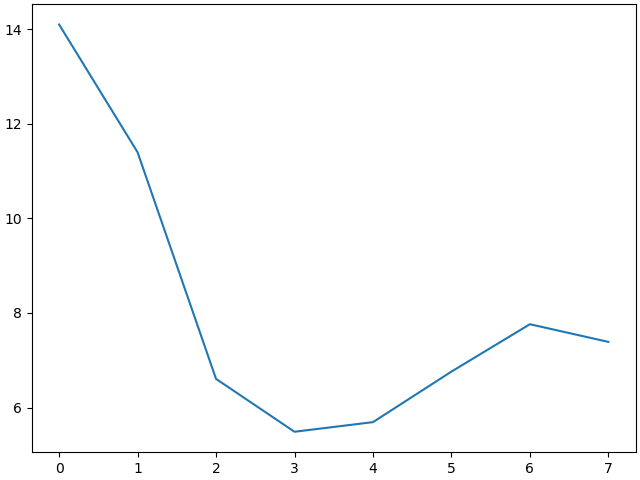

In [58]:
fig,ax=plt.subplots()
ax.plot(np.average(images, axis=(2,3)))

In [61]:
# Get one lambda value
if key == "master_energy":
    energy_lambda = cci.photon_energy_wavelength(scan_axis[0])
else: 
    energy_lambda = cci.photon_energy_wavelength(load_key(im_id, mnemonics["energy"]))

# Ugly handling of use subframes
try:
    scan_axis = np.stack(scan_axis)
except:
    scan_axis = np.concatenate(scan_axis)
try:
    scan_axis2 = np.stack(scan_axis2)
except:
    scan_axis2 = np.concatenate(scan_axis2)
try:
    norm = np.stack(norm)
except:
    norm = np.concatenate(norm)

try:
    images = np.stack(images)
except:
    images = np.concatenate(images)

# Squeeze list
images = np.squeeze(images)
scan_axis = np.squeeze(scan_axis)
scan_axis2 = np.squeeze(scan_axis2)
norm = np.squeeze(norm)

if key == "magnet_A":
    scan_axis = current_to_field(scan_axis)
    key = "magnet_mT"

# grouping by energy and m_bias

In [62]:
try:
    data = xr.Dataset()
    #data["index"] = im_ids
    data[key] = xr.DataArray(scan_axis, dims=["index", "frames"])
    data[key2] = xr.DataArray(scan_axis2, dims=["index", ])
    data["images"] = xr.DataArray(images, dims=["index", "frames","y", "x"])
    
    databin=data.groupby([key,key2]).mean()#["images"]
except Exception as e:
    try:
        print(e)
        data = xr.Dataset()
        #data["index"] = im_ids
        data[key] = xr.DataArray(scan_axis, dims=["index"])
        data[key2] = xr.DataArray(scan_axis2, dims=["index", ])
        data["images"] = xr.DataArray(images, dims=["index","y", "x"])
        
        databin=data.groupby([key,key2]).mean()#["images"] 
        
    except Exception as e:
        print(e)
        data = xr.Dataset()
        #data["index"] = im_ids
        #data[key] = xr.DataArray(scan_axis, dims=["index"])
        data[key2] = xr.DataArray(scan_axis2, dims=["index", "frames"])
        data["images"] = xr.DataArray(images, dims=["index","frames","y", "x"])
        
        databin=data.groupby([key2]).mean()#["images"] 


different number of dimensions on data and dims: 1 vs 2


# points for the linescans and roi

In [19]:
P2=[772,1022]
P1=[181,138]
P1=[87,0]


P2=[243, 305]
P1=[37,0]

P2=[396, 498]
P1=[122,112]

m=(P2[1]-P1[1])/(P2[0]-P1[0])
b=P1[0]-m*P1[1]


roi=np.s_[1180:1880, 1110:]
roi=np.s_[:,:]

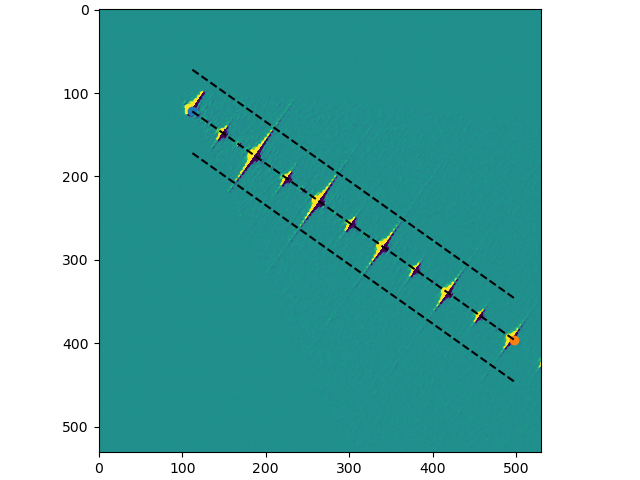

In [20]:
fig,ax=plt.subplots()

energy=455
m_bias=10
im1=databin.sel(m_bias=m_bias, method="nearest").sel(energy=energy, method="nearest")["images"].values
m_bias=0
im0=databin.sel(m_bias=m_bias, method="nearest").sel(energy=energy, method="nearest")["images"].values

ax.imshow(im1-im0  , vmin=-10, vmax=10)
ax.scatter(P1[1], P1[0])
ax.scatter(P2[1], P2[0])
ax.plot([P1[1], P2[1]],[P1[0]-50, P2[0]-50], ls="--", c="k")
ax.plot([P1[1], P2[1]],[P1[0]+50, P2[0]+50], ls="--", c="k")

ax.plot([P1[1], P2[1]],[P1[0], P2[0]], ls="--", c="k")

# dirty look

interactive(children=(FloatRangeSlider(value=(-117.58992553710938, 124.86093139651877), description='contrast'…

(<Figure size 700x700 with 1 Axes>, <Axes: >)

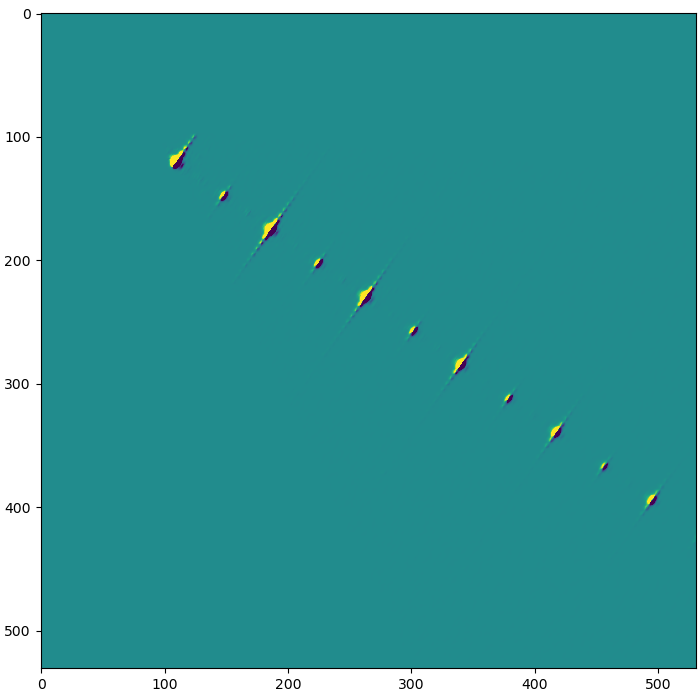

In [21]:
energy=455
m_bias=10
im1=databin.sel(m_bias=m_bias, method="nearest").sel(energy=energy, method="nearest")["images"].values
m_bias=0
im0=databin.sel(m_bias=m_bias, method="nearest").sel(energy=energy, method="nearest")["images"].values

cimshow(im1-im0, vmin=0,vmax=100)

Optimizing level 2 [max iter: 10000]
Optimizing level 1 [max iter: 1000]
Optimizing level 0 [max iter: 100]
Linear Fit: 0.7946*x + 0.0828
Optimizing level 2 [max iter: 10000]
Optimizing level 1 [max iter: 1000]
Optimizing level 0 [max iter: 100]
Linear Fit: 0.8653*x + 0.1163
Optimizing level 2 [max iter: 10000]
Optimizing level 1 [max iter: 1000]
Optimizing level 0 [max iter: 100]
Linear Fit: 0.7031*x + 0.2873
Optimizing level 2 [max iter: 10000]
Optimizing level 1 [max iter: 1000]
Optimizing level 0 [max iter: 100]
Linear Fit: 0.7749*x + 0.2260


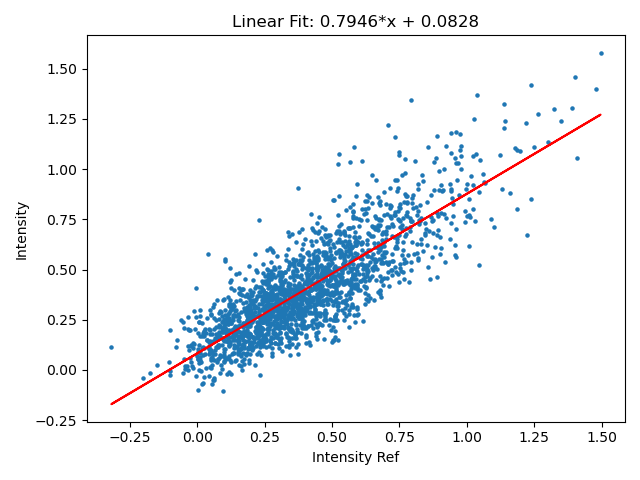

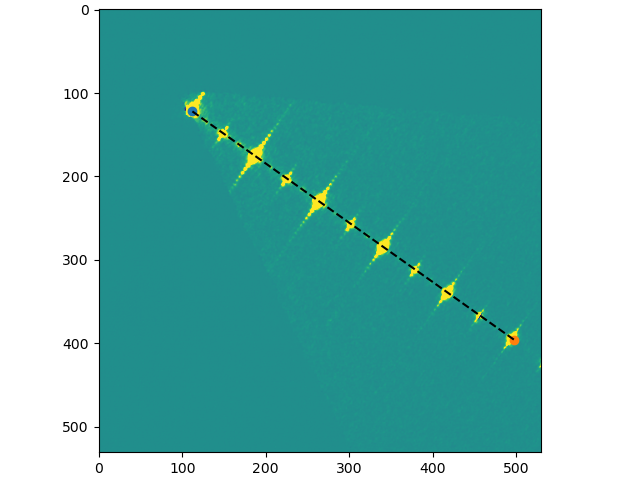

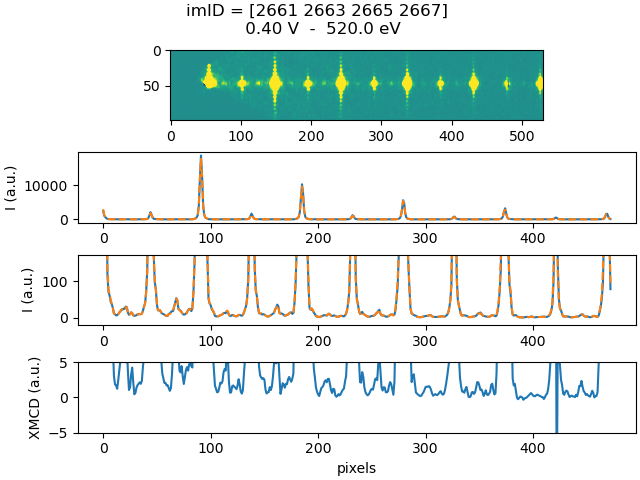

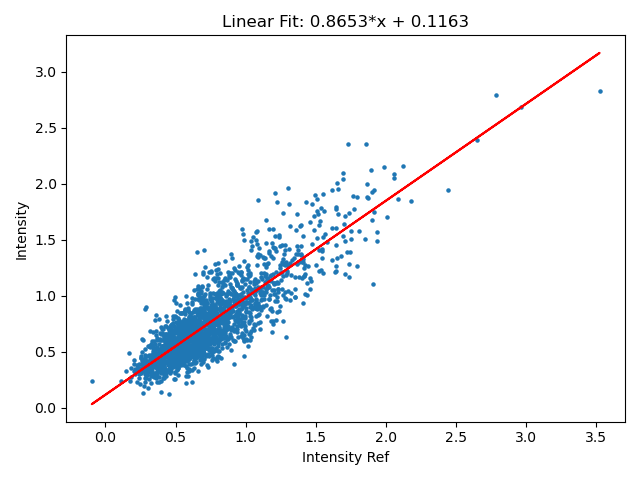

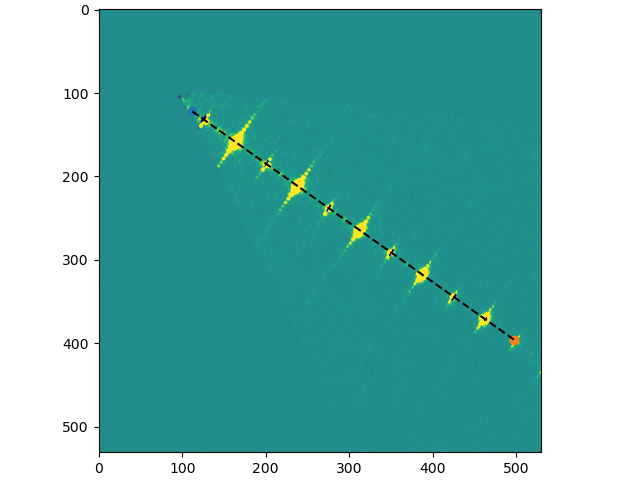

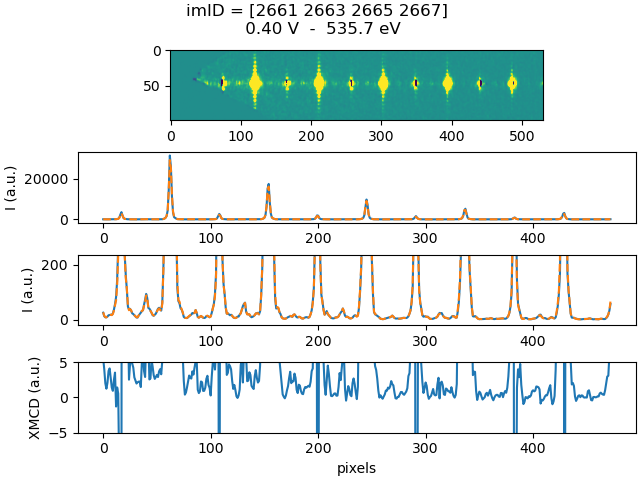

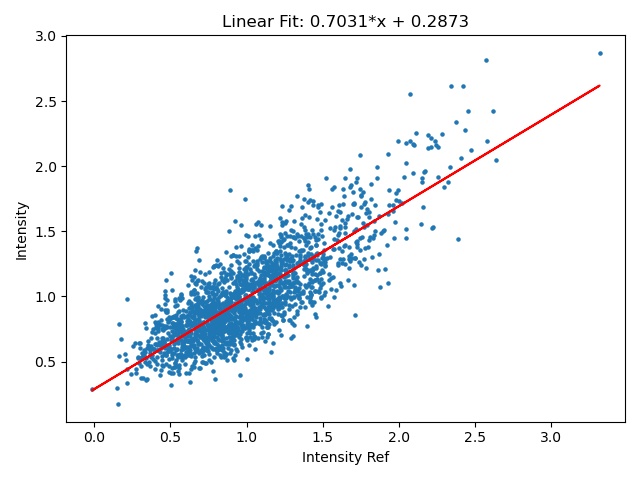

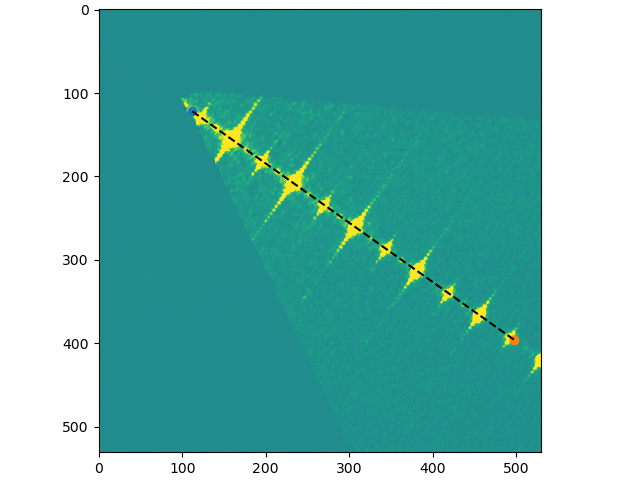

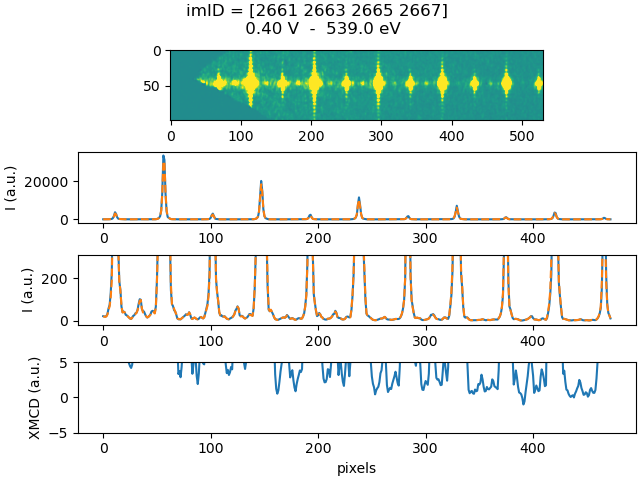

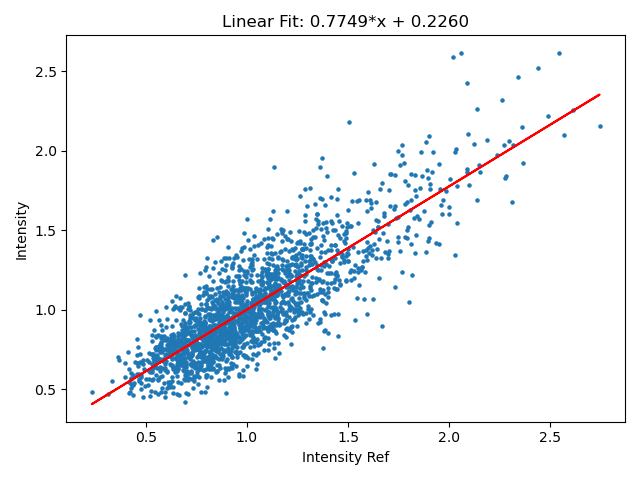

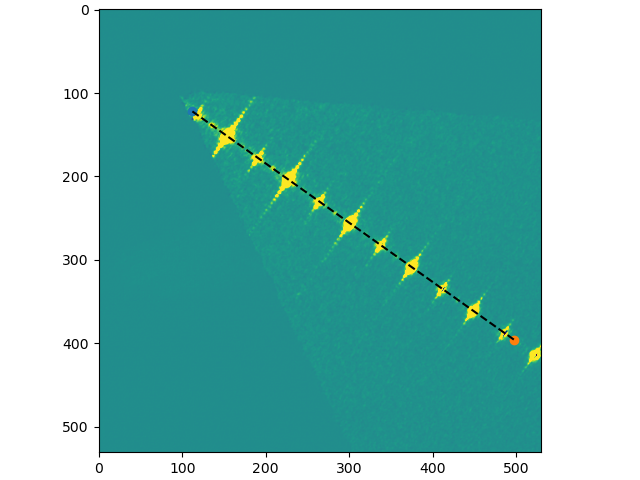

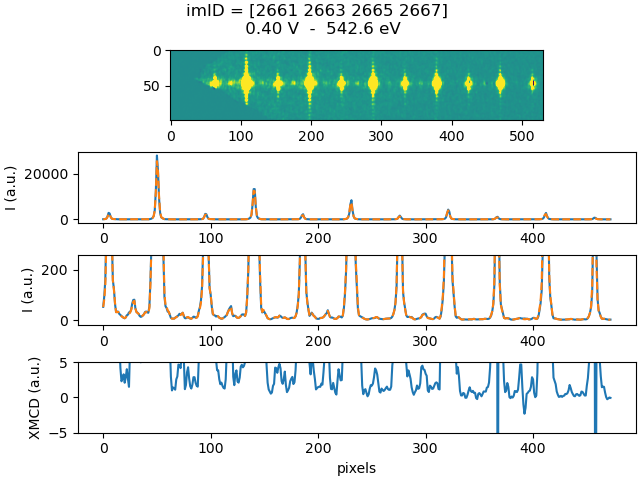

In [25]:
for energy in databin.energy.values:
    
    im=[0,0]
    for i in [0,1]:
        m_bias = databin.m_bias.values[i]
        im[i]=databin.sel(m_bias=m_bias, method="nearest").sel(energy=energy, method="nearest")["images"].values


    #SHIFT
    shift = cci.image_registration(
    im[0],
    im[1],
    method="dipy")
    im[1] = cci.shift_image(im[1], shift)


    
    #normalize
    # Get scaling factor and offset
    factor, offset = cci.dyn_factor(
        im[1][-20:,-100:],
        im[0][-20:,-100:] ,
        method="correlation",
        verbose=True,
        plot=True,
    )
    
    diff_c = im[1] / factor - im[0] - offset
    sum_c = im[1] / factor + im[0] - offset


    
    fig,ax=plt.subplots()
    ax.imshow((diff_c)  , vmin=-10, vmax=10)
    ax.scatter(P1[1], P1[0])
    ax.scatter(P2[1], P2[0])
    #ax.plot([P1[1], P2[1]],[P1[0]-50, P2[0]-50], ls="--", c="k")
    #ax.plot([P1[1], P2[1]],[P1[0]+50, P2[0]+50], ls="--", c="k")
    ax.plot([P1[1], P2[1]],[P1[0], P2[0]], ls="--", c="k")
    
    
    theta = np.arctan2(P1[1]- P2[1],P1[0]- P2[0])          # radians
    theta_deg = np.degrees(theta)       # degrees
    from scipy.ndimage import rotate
    diff2 = rotate(diff_c, angle=-theta_deg-90, reshape=False, order=1, mode="constant", cval=0.0)
    diff2=diff2[240-50:240+50]
    
    fig,ax=plt.subplots(4,1)
    ax[0].imshow((diff2)  , vmin=-10, vmax=10)
    linescan=line_scan((im[0][roi]), P1[1], P1[0], P2[1], P2[0], num=None)
    ax[1].plot(linescan)
    ax[2].plot(linescan)
    linescan=line_scan((im[1][roi]), P1[1], P1[0], P2[1], P2[0], num=None)
    ax[1].plot(linescan, ls="--")
    ax[2].plot(linescan, ls="--")
    mi,ma=np.percentile(linescan,(0,85))
    mi-=20
    #mi=-10
    ax[2].set_ylim(mi,ma)
    
    
    linescan=line_scan(((diff_c)[roi]), P1[1], P1[0], P2[1], P2[0], num=None)
    ax[3].plot(linescan, ls="-")
    ax[3].set_ylim(-5,5)
    #ax[0].set_xlabel("pixel")
    #ax[0].set_ylabel("pixel")
    #ax[1].set_xlabel("pixel")
    ax[3].set_xlabel("pixels")
    ax[1].set_ylabel("I (a.u.)")
    ax[2].set_ylabel("I (a.u.)")
    ax[3].set_ylabel("XMCD (a.u.)")
    
    
    fig.suptitle("imID = %s \n %0.2f V  -  %0.1f eV"%(im_ids, m_bias, energy))


    plt.savefig("/asap3/petra3/gpfs/p04/2026/data/11022228/processed/imID =%s_V=%0.2fV_E=%0.1feV.png"%(im_ids, m_bias, energy))